# Step 5: Momentum
**Ball value** = how much the ball moved the batting side's position.
- First innings: runs scored + change in expected runs still to come (so a wicket costs the runs it removes).
- Chase: change in the batting side's **win probability**.

**Momentum** = rolling sum over 10 balls of *actual value - expected value* (expected from the Step 4 classifier). Positive = the batting side is doing better than the situation and players predicted.

In [1]:
import os, json, warnings; warnings.filterwarnings('ignore'); ROOT=os.path.expanduser('~/hundred-momentum')
import numpy as np, pandas as pd, lightgbm as lgb, joblib, matplotlib.pyplot as plt
from sklearn.metrics import log_loss, roc_auc_score
R = pd.read_parquet(ROOT+'/data/clean/predictions.parquet'); ALLD = pd.read_parquet(ROOT+'/data/clean/features.parquet'); M = pd.read_parquet(ROOT+'/data/clean/matches.parquet')
RR = joblib.load(ROOT+'/data/clean/runs_left_model.pkl')
DEV = ALLD[(ALLD.season <= 2025) & (ALLD.full_match == 1)].copy(); DEV['cls'] = np.where(DEV.is_wicket == 1, 0, 1 + np.minimum(DEV.runs_total, 5))
K = ['W','0','1','2','3','4','5p']; cm = np.array([DEV.runs_total[DEV.cls == c].mean() for c in range(7)]); legal_k = np.array([DEV.legal[DEV.cls == c].mean() for c in range(7)])
print('mean runs per class', cm.round(2), '| share legal per class', legal_k.round(3))

mean runs per class [0.02 0.   1.   2.   3.   4.   5.98] | share legal per class [0.998 1.    0.934 0.934 0.649 0.998 0.95 ]


## 5.1 Win-probability model for chases
Inputs: runs needed, balls left, wickets in hand. Monotone: needing more runs can only lower the chance; more balls or wickets can only raise it. Trained on 2021-2025; checked on 2026.

In [2]:
def chase(d):
    d = d[(d.innings == 2)].merge(M[['match_id','winner','result']], on='match_id'); d = d[d.result == 'win']
    return d.assign(won=(d.batting_team == d.winner).astype(int), wih=10 - d.wkts_pre)
C = chase(DEV); T26 = chase(ALLD[(ALLD.season == 2026) & (ALLD.full_match == 1)])
WX = ['runs_needed', 'balls_left', 'wih']
WP = lgb.LGBMClassifier(n_estimators=500, learning_rate=.03, num_leaves=8, min_child_samples=150, monotone_constraints=[-1, 1, 1], random_state=0, verbose=-1).fit(C[WX], C.won)
for nm, d in [('train 2021-25', C), ('test 2026', T26)]:
    p = WP.predict_proba(d[WX])[:, 1]; p0 = np.full(len(d), C.won.mean())
    print(f'{nm}: balls {len(d)}, log-loss {log_loss(d.won, p):.4f} (constant {log_loss(d.won, p0):.4f}), AUC {roc_auc_score(d.won, p):.3f}, Brier {((p - d.won) ** 2).mean():.4f}')
def wp(need, balls, wih):
    need, balls, wih = map(lambda a: np.asarray(a, float), (need, balls, wih))
    p = WP.predict_proba(pd.DataFrame({'runs_needed': need, 'balls_left': np.maximum(balls, 1), 'wih': np.maximum(wih, 1)}))[:, 1]
    return np.where(need <= 0, 1.0, np.where((balls <= 0) | (wih <= 0), 0.0, p))
for need, b, w in [(30, 20, 5), (30, 20, 2), (10, 20, 5), (60, 30, 6)]: print(f'need {need} off {b}, {w} wickets in hand: win chance {wp([need],[b],[w])[0]:.2f}')
joblib.dump(WP, ROOT+'/data/clean/win_prob_model.pkl')

train 2021-25: balls 14612, log-loss 0.3726 (constant 0.6930), AUC 0.911, Brier 0.1221
test 2026: balls 3314, log-loss 0.4037 (constant 0.6924), AUC 0.895, Brier 0.1343
need 30 off 20, 5 wickets in hand: win chance 0.54
need 30 off 20, 2 wickets in hand: win chance 0.50
need 10 off 20, 5 wickets in hand: win chance 0.98
need 60 off 30, 6 wickets in hand: win chance 0.24


['/Users/mashadniyazi/hundred-momentum/data/clean/win_prob_model.pkl']

## 5.2 Value of every ball: actual and expected

In [3]:
Er = lambda b, w: np.where((np.asarray(w) <= 0) | (np.asarray(b) <= 0), 0.0, RR.predict(pd.DataFrame({'balls_left': np.asarray(b, float), 'wih': np.asarray(w, float)})))
d = R.copy(); w0 = 10 - d.wkts_pre.values; b0 = d.balls_left.values; P = d[[f'p_{k}' for k in K]].values
b1 = b0 - d.legal.values; w1 = w0 - d.is_wicket.values; r = d.runs_total.values
inn1 = d.innings.values == 1; need0 = d.runs_needed.values
act = np.where(inn1, r + Er(b1, w1) - Er(b0, w0), wp(need0 - r, b1, w1) - wp(need0, b0, w0))
exp = np.zeros(len(d))
for k in range(7):                 # outcome k, legal with probability legal_k[k]
    dw = 1 if k == 0 else 0
    for lg_, pl in [(1, legal_k[k]), (0, 1 - legal_k[k])]:
        v1 = cm[k] + Er(b0 - lg_, w0 - dw) - Er(b0, w0); v2 = wp(need0 - cm[k], b0 - lg_, w0 - dw) - wp(need0, b0, w0)
        exp += P[:, k] * pl * np.where(inn1, v1, v2)
d['value_actual'] = act; d['value_expected'] = exp; d['value_gap'] = act - exp
d['wp_pre'] = np.where(inn1, np.nan, wp(need0, b0, w0))
d = d.sort_values(['date','match_id','innings','seq']).reset_index(drop=True); g = d.groupby(['match_id','innings'], sort=False)
d['momentum'] = g.value_gap.transform(lambda x: x.rolling(10, min_periods=1).sum())
for i in (1, 2):
    z = d[d.innings == i]; u = 'runs' if i == 1 else 'win-prob points'
    print(f'innings {i} ({u}): mean actual {z.value_actual.mean():+.4f}, mean expected {z.value_expected.mean():+.4f}, mean gap {z.value_gap.mean():+.4f}, sd gap {z.value_gap.std():.4f}')
    print('   by event, mean gap:', z.groupby(np.select([z.is_wicket == 1, z.runs_bat >= 4, z.runs_total == 0], ['wicket','boundary','dot'], 'other')).value_gap.mean().round(4).to_dict())

innings 1 (runs): mean actual +0.0263, mean expected +0.0152, mean gap +0.0111, sd gap 2.3943
   by event, mean gap: {'boundary': 3.4551, 'dot': -1.0989, 'other': 0.0854, 'wicket': -5.6607}
innings 2 (win-prob points): mean actual +0.0001, mean expected -0.0000, mean gap +0.0001, sd gap 0.0443
   by event, mean gap: {'boundary': 0.041, 'dot': -0.0142, 'other': 0.0007, 'wicket': -0.0623}


## 5.3 Does momentum persist?
If momentum is real, a good last 10 balls (beyond what the model expected) should predict a good next 10 balls. Non-overlapping 10-ball windows, within innings, 2022-2026 (all out-of-sample). Interval from resampling whole matches.

In [4]:
def windows(z):
    out = []
    for _, x in z.groupby(['match_id','innings'], sort=False):
        v = x.value_gap.values; a = x.value_actual.values
        for s in range(10, len(v) - 9, 10): out.append((x.match_id.iloc[0], x.innings.iloc[0], x.season.iloc[0], v[s-10:s].sum(), v[s:s+10].sum(), a[s:s+10].sum(), x.value_expected.values[s:s+10].sum()))
    return pd.DataFrame(out, columns=['match_id','innings','season','past','future','future_actual','future_expected'])
W = windows(d); rng = np.random.default_rng(3)
def boot(f, z):
    um = z.match_id.unique(); pos = {q: np.where(z.match_id.values == q)[0] for q in um}; z = z.reset_index(drop=True)
    return np.percentile([f(z.iloc[np.concatenate([pos[q] for q in rng.choice(um, len(um))])]) for _ in range(2000)], [2.5, 97.5])
slope = lambda z: np.polyfit(z.past, z.future, 1)[0]
for i in (1, 2):
    z = W[W.innings == i]; hi = z.past > z.past.median()
    print(f'innings {i}: windows {len(z)}, corr(past, future) {z.past.corr(z.future):+.3f}, slope {slope(z):+.3f} 95% {boot(slope, z).round(3)}, future gap after HIGH {z.future[hi].mean():+.4f} v LOW {z.future[~hi].mean():+.4f}')
z = W[W.season == 2026]
for i in (1, 2): q = z[z.innings == i]; print(f'2026 only, innings {i}: windows {len(q)}, slope {slope(q):+.3f} 95% {boot(slope, q).round(3)}')
# raw scoring persistence, for contrast: past actual value v future actual value (no model adjustment)
W2 = W.assign(past_actual=d.groupby(['match_id','innings'], sort=False).apply(lambda x: pd.Series([x.value_actual.values[s-10:s].sum() for s in range(10, len(x) - 9, 10)])).values)
for i in (1, 2): q = W2[W2.innings == i]; print(f'raw scoring, innings {i}: corr(past actual, future actual) {q.past_actual.corr(q.future_actual):+.3f}')

innings 1: windows 1425, corr(past, future) +0.069, slope +0.068 95% [0.009 0.123], future gap after HIGH +0.5365 v LOW -0.1930


innings 2: windows 1296, corr(past, future) +0.090, slope +0.103 95% [0.002 0.199], future gap after HIGH +0.0026 v LOW -0.0092
2026 only, innings 1: windows 305, slope -0.003 95% [-0.133  0.116]


2026 only, innings 2: windows 281, slope -0.042 95% [-0.225  0.191]
raw scoring, innings 1: corr(past actual, future actual) +0.036
raw scoring, innings 2: corr(past actual, future actual) -0.059


## 5.4 Momentum graphs (2026 test matches)

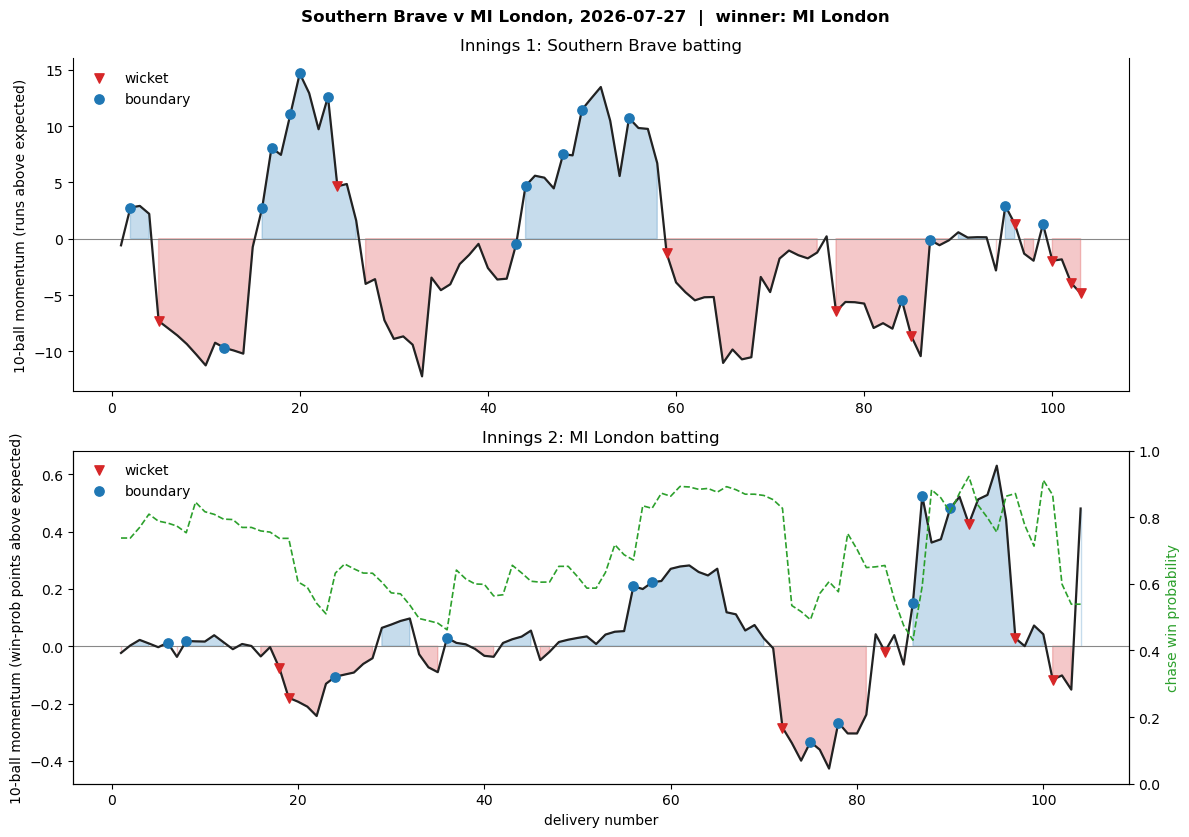

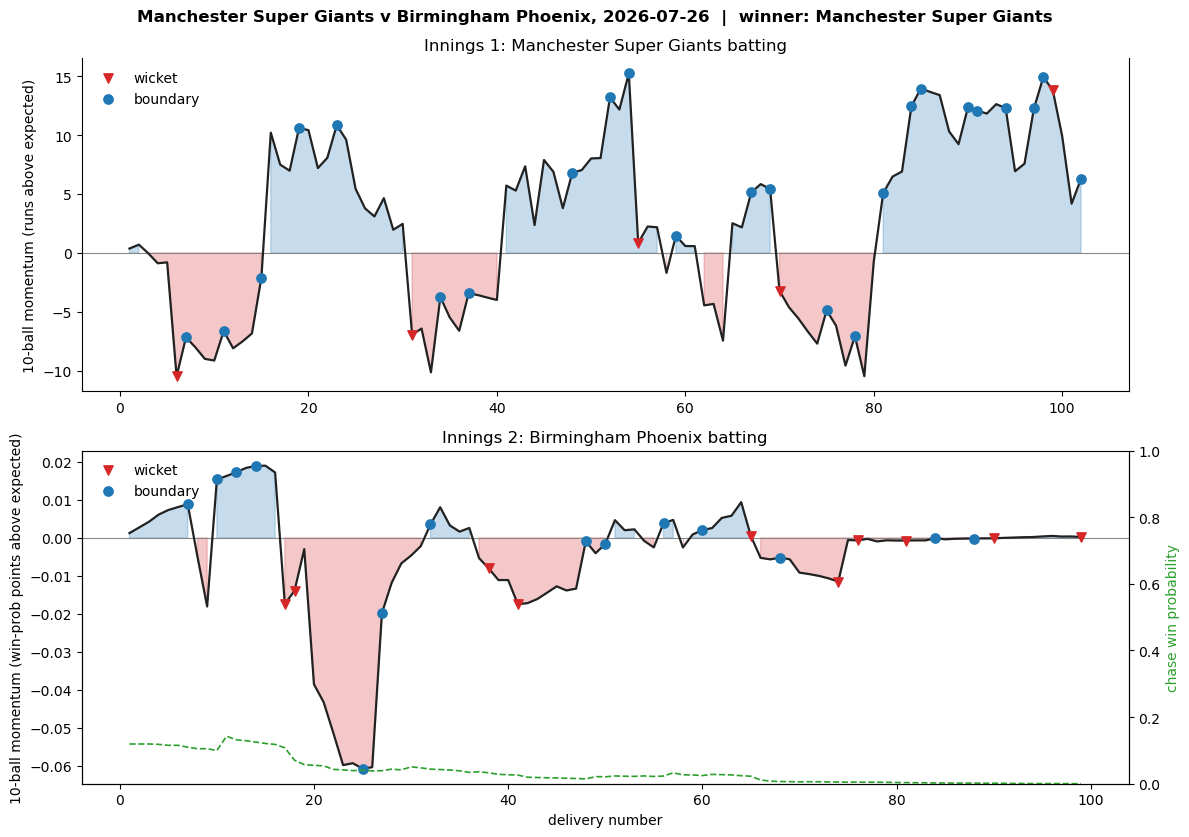

In [5]:
def plot(mid, fn):
    x = d[d.match_id == mid]; info = M.set_index('match_id').loc[mid]
    fig, ax = plt.subplots(2, 1, figsize=(12, 8.5))
    for a, i in zip(ax, (1, 2)):
        z = x[x.innings == i]; bn = np.arange(1, len(z) + 1)
        a.axhline(0, color='#888', lw=.8); a.fill_between(bn, z.momentum, 0, where=z.momentum >= 0, color='#1f77b4', alpha=.25); a.fill_between(bn, z.momentum, 0, where=z.momentum < 0, color='#d62728', alpha=.25)
        a.plot(bn, z.momentum, color='#222', lw=1.6)
        for ev, mk, col in [(z.is_wicket == 1, 'v', '#d62728'), (z.runs_bat >= 4, 'o', '#1f77b4')]: a.scatter(bn[ev.values], z.momentum[ev.values], marker=mk, color=col, s=45, zorder=3, label='wicket' if mk == 'v' else 'boundary')
        u = 'runs above expected' if i == 1 else 'win-prob points above expected'
        a.set_title(f'Innings {i}: {z.batting_team.iloc[0]} batting'); a.set_ylabel(f'10-ball momentum ({u})'); a.legend(frameon=False, loc='upper left')
        if i == 2:
            a2 = a.twinx(); a2.plot(bn, z.wp_pre, color='#2ca02c', lw=1.2, ls='--'); a2.set_ylim(0, 1); a2.set_ylabel('chase win probability', color='#2ca02c')
        for s in ('top',): a.spines[s].set_visible(False)
    ax[1].set_xlabel('delivery number'); fig.suptitle(f"{info.team1} v {info.team2}, {str(info.date)[:10]}  |  winner: {info.winner}", fontweight='bold'); fig.tight_layout(); fig.savefig(ROOT+f'/figures/{fn}.png', dpi=150); plt.show()
mm = M[(M.season == 2026) & (M.full_match == 1) & (M.result == 'win')].copy()
mm['closeness'] = np.where(mm.by_runs.notna(), mm.by_runs, d[d.innings == 2].groupby('match_id').balls_left.last().reindex(mm.match_id).values)
close = mm.sort_values('closeness').match_id.iloc[0]; big = mm[mm.by_runs.notna()].sort_values('by_runs').match_id.iloc[-1]
plot(close, 'momentum_close_match'); plot(big, 'momentum_one_sided_match')

In [6]:
cols = ['match_id','date','season','innings','seq','ball_no','batting_team','bowling_team','batting_franchise','bowling_franchise','batter','bowler','runs_total','runs_bat','is_wicket','wicket_kind','score_pre','wkts_pre','balls_left','runs_needed','wp_pre','exp_runs','p_W','p_4','p_5p','value_actual','value_expected','value_gap','momentum']
d[cols].to_csv(ROOT+'/data/clean/momentum.csv', index=False); W.to_csv(ROOT+'/data/clean/momentum_windows.csv', index=False); print('saved', d.shape)

saved (31732, 120)
